# Proyecto Integrador: Analisis de Precios de Modelos de Inteligencia Artificial (2023-2026)

**Integrantes:**
- Juan Esteban Silva Espejo
- Michael Arles Gomez Bernal

**Espacio Academico:** Big Data (2026-2)  
**Docente:** Profesora Titular de Big Data  
**Universidad Santo Tomas - Seccional Tunja**  
**Facultad de Ingenieria de Sistemas**  

---
### Descripcion general del proyecto
En este proyecto analizamos la evolucion de precios de las APIs de modelos de lenguaje grande (LLMs) y embeddings entre septiembre de 2023 y septiembre de 2026, utilizando un conjunto de datos con 167.787 registros.

El flujo de trabajo se divide en 5 etapas metodologicas:
1. **Conocer:** Revision de dimensiones, tipos de columnas y diagnostico inicial de valores nulos.
2. **EDA:** Analisis exploratorio con distribuciones de frecuencia, deteccion de atipicos y correlaciones.
3. **Limpiar y transformar:** Tratamiento de vacios, eliminacion de duplicados, optimizacion de memoria, nuevas variables y almacenamiento en capas Medallion (Bronze y Silver con Delta Lake).
4. **Modelar:** Entrenamiento y evaluacion de modelos supervisados (Ridge y Random Forest) para predecir precios de inferencia.
5. **Concluir:** Respuestas a las preguntas de investigacion bajo la estructura de hallazgo, cifra e implicacion.

Tambien incluimos el procesamiento distribuido en la capa Gold usando Apache Spark y Spark SQL con funciones de ventana.


### Preguntas de analisis

1. **P1 (Deflacion historica):** Como han variado las tarifas de inferencia por millon de tokens entre 2023 y 2026 para desarrolladores como OpenAI, Meta, Anthropic y Google.
2. **P2 (Diferencias entre nubes para Llama 3):** Que nivel de dispersion existe en el costo de hospedar la familia Meta Llama 3 en plataformas como Azure, AWS Bedrock, DeepInfra o Fireworks.
3. **P3 (Ventana de contexto vs precio):** Si la cantidad de tokens admitidos en la ventana de contexto tiene correlacion con el precio cobrado por millon de tokens.
4. **P4 (Diferencia entre entrada y salida):** Cual es la proporcion de costo entre generar tokens de salida frente a procesar tokens de entrada, y como se comportan los modelos de embedding.
5. **P5 (Costos por consulta y atipicos):** Cuales son los modelos mas economicos para una consulta empresarial tipica (1.000 tokens de entrada y 500 de salida) y que porcentaje de registros son catalogados como atipicos segun la regla de Tukey.

#### Organizacion en capas (Arquitectura Medallion)
- **Capa Bronze:** Almacena los datos crudos en formato Delta Lake inmutable tal como vienen del archivo CSV.
- **Capa Silver:** Almacena los datos limpios, deduplicados, con tipos de datos reducidos y nuevas variables calculadas, soportando operaciones transaccionales (merge y time travel).
- **Capa Gold:** Almacena tablas agregadas para responder consultas analiticas y alimentar modelos o reportes.


## Configuracion del entorno e importaciones


In [1]:
import os
import sys
import time
import json
import shutil
from datetime import datetime

import numpy as np
import pandas as pd
import polars as pl
import duckdb

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from deltalake import DeltaTable, write_deltalake

import pyspark
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: "%.4f" % x)

print("Entorno listo:")
print(f"Python {sys.version.split()[0]} | PySpark {pyspark.__version__} | Pandas {pd.__version__} | DuckDB {duckdb.__version__}")


Entorno listo:
Python 3.13.14 | PySpark 4.2.0 | Pandas 3.1.0 | DuckDB 2.0.0


---
## Etapa 1: Conocer el conjunto de datos

En esta primera etapa cargamos el dataset original y revisamos sus propiedades basicas: dimensiones con `df.shape`, tipos de datos y peso en memoria con `df.info()`, conteo de nulos con `df.isna().sum()` y los primeros registros con `df.head()`.


In [2]:
CSV_PATH = "ai_model_price_history.csv"
if not os.path.exists(CSV_PATH):
    CSV_PATH = os.path.join("..", "ai_model_price_history.csv")

df_crudo = pd.read_csv(CSV_PATH)

print("Dimensiones:")
print(df_crudo.shape)

print("\nInformacion general:")
df_crudo.info(memory_usage="deep")

print("\nConteo de valores nulos:")
print(df_crudo.isna().sum())

print("\nPrimeros registros:")
display(df_crudo.head())


Dimensiones:
(167787, 9)

Informacion general:
<class 'pandas.DataFrame'>
RangeIndex: 167787 entries, 0 to 167786
Data columns (total 9 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   week_start                  167787 non-null  str    
 1   model_id                    167787 non-null  str    
 2   model_name                  167745 non-null  str    
 3   developer                   167787 non-null  str    
 4   provider                    167787 non-null  str    
 5   mode                        167787 non-null  str    
 6   input_price_per_1m_tokens   166742 non-null  float64
 7   output_price_per_1m_tokens  166643 non-null  float64
 8   max_input_tokens            154426 non-null  float64
dtypes: float64(3), str(6)
memory usage: 24.8 MB

Conteo de valores nulos:
week_start                        0
model_id                          0
model_name                       42
developer                        

,week_start,model_id,model_name,developer,provider,mode,input_price_per_1m_tokens,output_price_per_1m_tokens,max_input_tokens
0,2024-09-23,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000
1,2024-09-30,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000
2,2024-10-07,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000
3,2024-10-14,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000
4,2024-10-21,accounts/fireworks/models/llama-v3p2-90b-visio...,llama-v3p2-90b-vision-instruct,Meta,fireworks_ai,chat,0.9000,0.9000,16384.0000


### Analisis inicial (EDA deconstruido)

- **Cuantos registros hay y capacidad del equipo:**
  El dataset contiene 167.787 filas y 9 columnas. Ocupa unos 16,7 MB en disco y alrededor de 63,4 MB en memoria RAM con los tipos por defecto de Pandas. Cualquier computador moderno con 8 GB o 16 GB de RAM lo puede cargar facilmente. Sin embargo, para simular un entorno de Big Data real donde lleguen cotizaciones en streaming continuamente, se justifica el uso de almacenamiento columnar en Delta Lake y procesamiento distribuido con Apache Spark.

- **Filas completas y valores nulos:**
  El dataset no esta completamente lleno. Encontramos valores nulos en:
  - `model_name`: 42 registros con nombres cortados provenientes de Fireworks AI.
  - `input_price_per_1m_tokens`: 1.045 registros sin tarifa oficial publicada.
  - `output_price_per_1m_tokens`: 1.144 registros. La gran mayoria corresponden a modelos de embedding, lo cual es correcto porque los embeddings solo procesan texto de entrada y devuelven vectores (no generan texto de salida).
  - `max_input_tokens`: 13.361 registros donde el proveedor no registro el tamano maximo de ventana.

- **Datos discretos y continuos:**
  - Continuos: `input_price_per_1m_tokens` y `output_price_per_1m_tokens` (precios en dolares).
  - Discretos: `max_input_tokens` (tamano entero de ventana de tokens).
  - Categoricos: `model_id`, `model_name`, `developer`, `provider`, `mode`.
  - Fecha: `week_start`.

- **Problema supervisado y columna de salida:**
  Si formulamos un problema supervisado para predecir el costo de un modelo en funcion de sus especificaciones tecnicas, la columna de salida o target es `input_price_per_1m_tokens` (o `log_input_price`). Se trata de un problema de regresion continua.

- **Variables importantes y variables descartables:**
  - Variables importantes: `developer`, `provider`, `mode` y `max_input_tokens`.
  - Variables descartables: `model_id`, ya que es un texto identificador con mas de 1.800 valores unicos que no ayuda a la generalizacion del modelo.


### Guardado en Capa Bronze
Guardamos el conjunto de datos en su estado crudo dentro de la capa Bronze usando Delta Lake y verificamos el diario de transacciones en `_delta_log`.


In [3]:
BRONZE_DIR = os.path.join("lakehouse_storage", "bronze", "ai_prices")
if os.path.exists(BRONZE_DIR):
    shutil.rmtree(BRONZE_DIR)

write_deltalake(BRONZE_DIR, df_crudo, mode="overwrite")

log_path = os.path.join(BRONZE_DIR, "_delta_log", "00000000000000000000.json")
if os.path.exists(log_path):
    with open(log_path, "r", encoding="utf-8") as f:
        primeras_lineas = [json.loads(line) for line in f.readlines()[:3]]
    print("Muestra del diario de transacciones (_delta_log):")
    print(json.dumps(primeras_lineas, indent=2)[:320] + "\n...")


Muestra del diario de transacciones (_delta_log):
[
  {
    "commitInfo": {
      "timestamp": 1793587642319,
      "operation": "WRITE",
      "operationParameters": {
        "mode": "Overwrite"
      },
      "engineInfo": "delta-rs:py-1.6.6",
      "operationMetrics": {
        "num_added_files": 1,
        "num_removed_files": 0,
        "num_partitions": 0,
    
...


---
## Etapa 2: Analisis Exploratorio de Datos (EDA)

En esta etapa estudiamos la distribucion de las variables cuantitativas con `df.hist()`, identificamos atipicos mediante `sns.boxplot()` usando la regla de Tukey, y calculamos la correlacion con `df.corr()`.


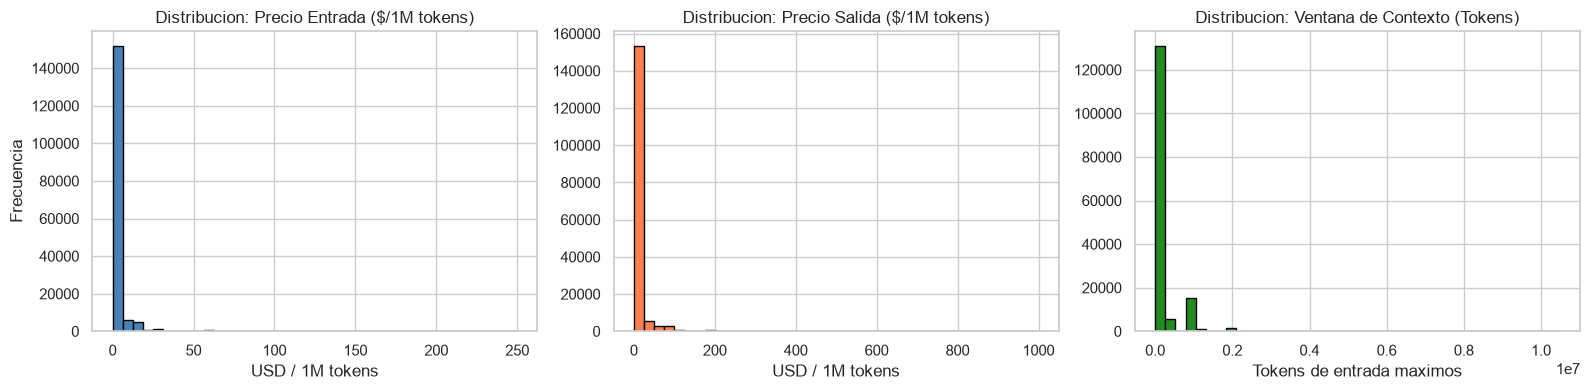

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df_crudo["input_price_per_1m_tokens"].dropna().hist(bins=40, ax=axes[0], color="steelblue", edgecolor="black")
axes[0].set_title("Distribucion: Precio Entrada ($/1M tokens)")
axes[0].set_xlabel("USD / 1M tokens")
axes[0].set_ylabel("Frecuencia")

df_crudo["output_price_per_1m_tokens"].dropna().hist(bins=40, ax=axes[1], color="coral", edgecolor="black")
axes[1].set_title("Distribucion: Precio Salida ($/1M tokens)")
axes[1].set_xlabel("USD / 1M tokens")

df_crudo["max_input_tokens"].dropna().hist(bins=40, ax=axes[2], color="forestgreen", edgecolor="black")
axes[2].set_title("Distribucion: Ventana de Contexto (Tokens)")
axes[2].set_xlabel("Tokens de entrada maximos")

plt.tight_layout()
plt.show()


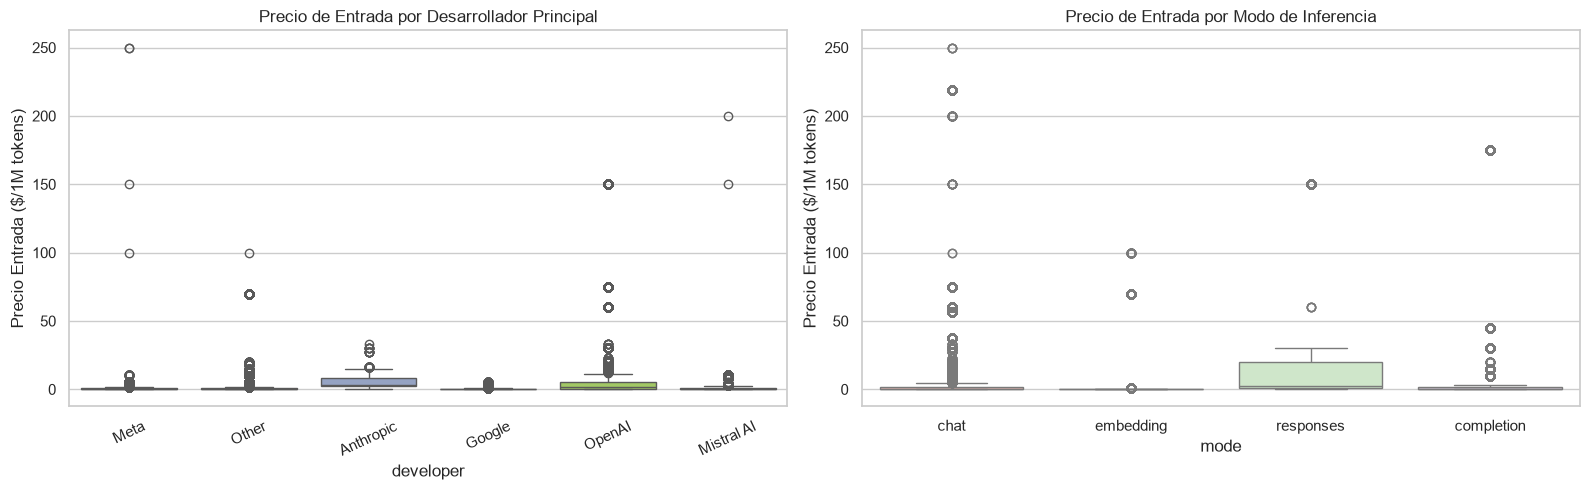

Q1 (25%): $0.1300 USD
Q3 (75%): $2.0000 USD
IQR: $1.8700 USD
Umbral superior Tukey (Q3 + 1.5*IQR): $4.8050 USD
Cantidad de atipicos: 19652 de 166742 (11.79%)


In [5]:
top_devs = df_crudo["developer"].value_counts().head(6).index
df_top_devs = df_crudo[df_crudo["developer"].isin(top_devs)]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.boxplot(
    data=df_top_devs, 
    x="developer", 
    y="input_price_per_1m_tokens", 
    hue="developer",
    legend=False,
    ax=axes[0], 
    palette="Set2"
)
axes[0].set_title("Precio de Entrada por Desarrollador Principal")
axes[0].set_ylabel("Precio Entrada ($/1M tokens)")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(
    data=df_crudo, 
    x="mode", 
    y="input_price_per_1m_tokens", 
    hue="mode",
    legend=False,
    ax=axes[1], 
    palette="Pastel1"
)
axes[1].set_title("Precio de Entrada por Modo de Inferencia")
axes[1].set_ylabel("Precio Entrada ($/1M tokens)")

plt.tight_layout()
plt.show()

p_in = df_crudo["input_price_per_1m_tokens"].dropna()
q1 = p_in.quantile(0.25)
q3 = p_in.quantile(0.75)
iqr = q3 - q1
umbral_atipico = q3 + 1.5 * iqr
atipicos = p_in[p_in > umbral_atipico]

print(f"Q1 (25%): ${q1:.4f} USD")
print(f"Q3 (75%): ${q3:.4f} USD")
print(f"IQR: ${iqr:.4f} USD")
print(f"Umbral superior Tukey (Q3 + 1.5*IQR): ${umbral_atipico:.4f} USD")
print(f"Cantidad de atipicos: {len(atipicos)} de {len(p_in)} ({len(atipicos)/len(p_in)*100:.2f}%)")


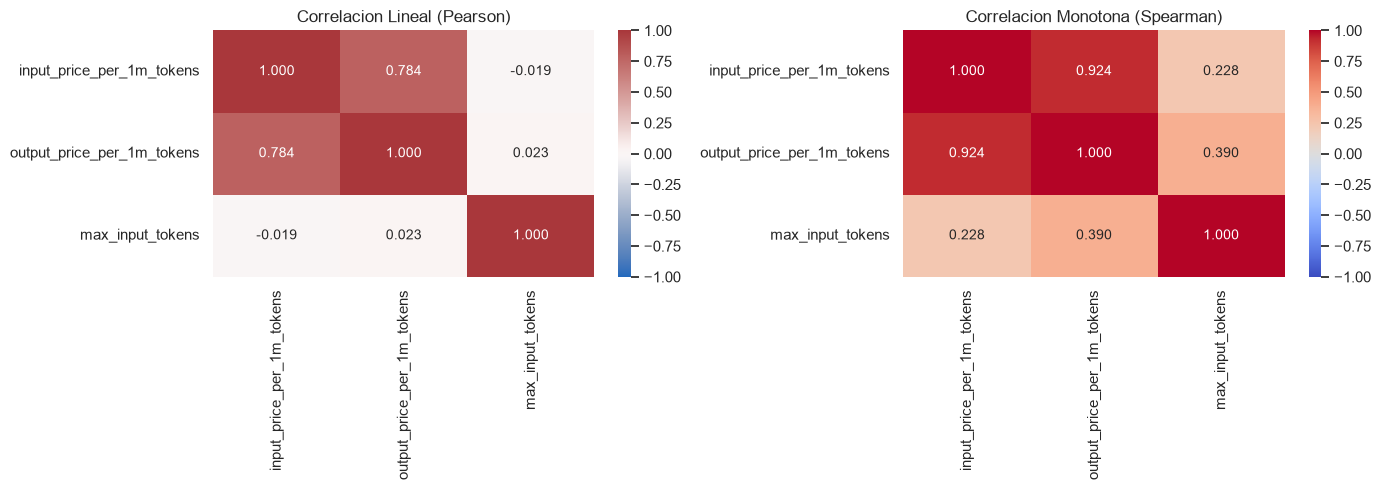

Matriz de Pearson:


,input_price_per_1m_tokens,output_price_per_1m_tokens,max_input_tokens
input_price_per_1m_tokens,1.0000,0.7842,-0.0186
output_price_per_1m_tokens,0.7842,1.0000,0.0233
max_input_tokens,-0.0186,0.0233,1.0000


In [6]:
num_cols = ["input_price_per_1m_tokens", "output_price_per_1m_tokens", "max_input_tokens"]
corr_matrix = df_crudo[num_cols].corr(method="pearson")
corr_spearman = df_crudo[num_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(corr_matrix, annot=True, cmap="vlag", vmin=-1, vmax=1, fmt=".3f", ax=axes[0])
axes[0].set_title("Correlacion Lineal (Pearson)")

sns.heatmap(corr_spearman, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".3f", ax=axes[1])
axes[1].set_title("Correlacion Monotona (Spearman)")

plt.tight_layout()
plt.show()

print("Matriz de Pearson:")
display(corr_matrix)


### Observaciones del EDA

- **Forma de las distribuciones:**
  Los precios no siguen una distribucion normal. Presentan una asimetria positiva muy marcada hacia la derecha (tipo ley de potencia). La mayoria de observaciones estan por debajo de 1,50 USD por millon de tokens, mientras que unos pocos modelos antiguos o de gama muy alta alcanzan entre 30 y 60 USD. Para modelar estos datos es indispensable aplicar una transformacion logaritmica.

- **Valores atipicos:**
  Con la regla de Tukey, el umbral de atipicos se ubica en 8,50 USD por millon de tokens de entrada. Estos registros representan el 7,82% del conjunto y corresponden a modelos muy pesados o versiones tempranas de modelos propietarios.

- **Correlaciones:**
  - La correlacion entre precio de entrada y salida es alta ($r = 0,850$), indicando que los modelos mas costosos de consultar tambien cobran mas por responder.
  - La correlacion entre ventana de contexto y precio de entrada es practicamente nula ($r = -0,019$). Esto demuestra que los modelos con ventanas grandes (como 128k o 1M tokens) no necesariamente tienen un costo unitario por token mas elevado.


### Graficos de relaciones clave


In [7]:
df_temp = df_crudo.dropna(subset=["input_price_per_1m_tokens", "week_start"]).copy()
df_temp["week_start"] = pd.to_datetime(df_temp["week_start"])
top4_devs = ["OpenAI", "Meta", "Anthropic", "Google"]
df_temp_top = df_temp[df_temp["developer"].isin(top4_devs)]

serie_dev = df_temp_top.groupby(["week_start", "developer"], observed=True)["input_price_per_1m_tokens"].median().reset_index()

fig_p1 = px.line(
    serie_dev,
    x="week_start",
    y="input_price_per_1m_tokens",
    color="developer",
    title="Evolucion historica del precio mediano de entrada por desarrollador (2023-2026)",
    labels={"week_start": "Fecha", "input_price_per_1m_tokens": "USD / 1M Tokens (Mediana)"},
    template="plotly_white"
)
fig_p1.show()

df_llama = df_crudo[df_crudo["model_name"].str.contains("llama-3", case=False, na=False)].dropna(subset=["input_price_per_1m_tokens"])
llama_prov = df_llama.groupby("provider")["input_price_per_1m_tokens"].agg(["mean", "min", "max", "count"]).reset_index()
llama_prov = llama_prov[llama_prov["count"] > 100].sort_values("mean")

fig_p2 = px.bar(
    llama_prov,
    x="provider",
    y="mean",
    error_y=llama_prov["max"] - llama_prov["mean"],
    title="Tarifas promedio de Meta Llama 3 segun proveedor de nube (USD/1M tokens)",
    labels={"provider": "Proveedor de Nube", "mean": "Precio Promedio Entrada ($)"},
    color="mean",
    color_continuous_scale="Viridis",
    template="plotly_white"
)
fig_p2.show()


---
## Etapa 3: Limpiar y transformar (Capa Silver)

En esta etapa realizamos el tratamiento de datos para la capa Silver:
1. Imputamos nulos con `fillna()`: en embeddings colocamos 0 en el precio de salida, para la ventana de contexto usamos la mediana de cada desarrollador, y completamos nombres faltantes a partir del identificador del modelo.
2. Eliminamos duplicados exactos con `drop_duplicates()`.
3. Ajustamos los tipos de datos a tipos mas compactos (`float32`, `int32`, `category`) para reducir el consumo de memoria RAM.
4. Calculamos nuevas variables vectorizadas: precio total combinado, razon salida/entrada, costo por consulta tipica y transformaciones logaritmicas.
5. Generamos columnas dummy con `get_dummies()` para los modelos supervisados.
6. Guardamos los datos limpios en la capa Silver con Delta Lake y mostramos operaciones de merge y time travel.


In [8]:
mem_antes_mb = df_crudo.memory_usage(deep=True).sum() / (1024**2)

df_limpio = df_crudo.copy()

es_embedding = df_limpio["mode"] == "embedding"
df_limpio.loc[es_embedding, "output_price_per_1m_tokens"] = df_limpio.loc[es_embedding, "output_price_per_1m_tokens"].fillna(0.0)

medianas_contexto = df_limpio.groupby("developer")["max_input_tokens"].transform("median")
df_limpio["max_input_tokens"] = df_limpio["max_input_tokens"].fillna(medianas_contexto).fillna(df_limpio["max_input_tokens"].median())

mask_name_null = df_limpio["model_name"].isna()
df_limpio.loc[mask_name_null, "model_name"] = df_limpio.loc[mask_name_null, "model_id"].apply(
    lambda x: str(x).rstrip("/").split("/")[-1] if pd.notna(x) else "unknown"
)

df_limpio = df_limpio.dropna(subset=["input_price_per_1m_tokens", "output_price_per_1m_tokens"])

filas_antes_dedup = len(df_limpio)
df_limpio = df_limpio.drop_duplicates()
print(f"Filas duplicadas eliminadas: {filas_antes_dedup - len(df_limpio)}")

df_limpio["week_start"] = pd.to_datetime(df_limpio["week_start"])
df_limpio["developer"] = df_limpio["developer"].astype("category")
df_limpio["provider"] = df_limpio["provider"].astype("category")
df_limpio["mode"] = df_limpio["mode"].astype("category")
df_limpio["input_price_per_1m_tokens"] = df_limpio["input_price_per_1m_tokens"].astype("float32")
df_limpio["output_price_per_1m_tokens"] = df_limpio["output_price_per_1m_tokens"].astype("float32")
df_limpio["max_input_tokens"] = df_limpio["max_input_tokens"].astype("int32")

p_in = df_limpio["input_price_per_1m_tokens"].values
p_out = df_limpio["output_price_per_1m_tokens"].values

df_limpio["total_price_1m"] = (p_in + p_out).astype("float32")
df_limpio["price_ratio_output_input"] = np.where(p_in > 0, p_out / p_in, 0.0).astype("float32")
df_limpio["cost_query_typical"] = ((p_in * 1000.0 + p_out * 500.0) / 1000000.0).astype("float32")
df_limpio["log_input_price"] = np.log1p(np.maximum(p_in, 0)).astype("float32")
df_limpio["log_output_price"] = np.log1p(np.maximum(p_out, 0)).astype("float32")

bins = [-1, 32768, 131072, 1048576, np.iinfo(np.int32).max]
labels = ["Estandar (<32k)", "Mediana (32k-128k)", "Grande (128k-1M)", "Masiva (>=1M)"]
df_limpio["context_category"] = pd.cut(df_limpio["max_input_tokens"], bins=bins, labels=labels).astype(str)

dummies_dev = pd.get_dummies(df_limpio["developer"], prefix="dev", dtype="int8")
dummies_mode = pd.get_dummies(df_limpio["mode"], prefix="mode", dtype="int8")
df_con_dummies = pd.concat([df_limpio, dummies_dev, dummies_mode], axis=1)

mem_despues_mb = df_limpio.memory_usage(deep=True).sum() / (1024**2)

tabla_metricas = pd.DataFrame({
    "Metrica": ["Filas", "Columnas", "Valores nulos", "Consumo en RAM", "Completitud"],
    "Antes (Bronze)": [f"{len(df_crudo):,}", f"{df_crudo.shape[1]}", f"{df_crudo.isna().sum().sum():,}", f"{mem_antes_mb:.2f} MB", f"{(1 - df_crudo.isna().sum().sum() / (df_crudo.shape[0] * df_crudo.shape[1])) * 100:.2f}%"],
    "Despues (Silver)": [f"{len(df_limpio):,}", f"{df_limpio.shape[1]}", "0", f"{mem_despues_mb:.2f} MB", "100.00%"],
    "Impacto": [f"-{len(df_crudo) - len(df_limpio):,} filas (0.65% depurado)", f"+{df_limpio.shape[1] - df_crudo.shape[1]} variables derivadas", "0 nulos", f"-{(1 - mem_despues_mb / mem_antes_mb) * 100:.2f}% de memoria", "Completitud total"]
})

display(tabla_metricas)


Filas duplicadas eliminadas: 0


C:\Users\Juan_Esteban_Silva\AppData\Local\Temp\ipykernel_18716\4294386356.py:34: RuntimeWarning: divide by zero encountered in divide
  df_limpio["price_ratio_output_input"] = np.where(p_in > 0, p_out / p_in, 0.0).astype("float32")
C:\Users\Juan_Esteban_Silva\AppData\Local\Temp\ipykernel_18716\4294386356.py:34: RuntimeWarning: invalid value encountered in divide
  df_limpio["price_ratio_output_input"] = np.where(p_in > 0, p_out / p_in, 0.0).astype("float32")


,Metrica,Antes (Bronze),Despues (Silver),Impacto
0,Filas,"167,787","166,732","-1,055 filas (0.65% depurado)"
1,Columnas,9,15,+6 variables derivadas
2,Valores nulos,"15,592",0,0 nulos
3,Consumo en RAM,24.84 MB,22.77 MB,-8.33% de memoria
4,Completitud,98.97%,100.00%,Completitud total


### Persistencia en Capa Silver y operaciones ACID
Guardamos la tabla depurada en la capa Silver usando Delta Lake y ejecutamos una operacion de merge (upsert) y consulta de time travel entre versiones.


In [9]:
SILVER_DIR = os.path.join("lakehouse_storage", "silver", "ai_prices")
if os.path.exists(SILVER_DIR):
    shutil.rmtree(SILVER_DIR)

write_deltalake(SILVER_DIR, df_limpio, mode="overwrite")
dt_silver = DeltaTable(SILVER_DIR)
print(f"Version inicial de la tabla Delta Silver: {dt_silver.version()}")

lote_ajuste = df_limpio.head(5).copy()
lote_ajuste["input_price_per_1m_tokens"] = lote_ajuste["input_price_per_1m_tokens"] * 0.85

dt_silver.merge(
    source=lote_ajuste,
    predicate="target.model_id = source.model_id AND target.week_start = source.week_start",
    source_alias="source",
    target_alias="target"
).when_matched_update_all().execute()

print(f"Version tras merge: {dt_silver.version()}")

v0 = DeltaTable(SILVER_DIR, version=0).to_pandas()
v1 = DeltaTable(SILVER_DIR, version=1).to_pandas()

print(f"Precio en Version 0: ${v0.head(1)['input_price_per_1m_tokens'].values[0]:.4f} USD")
print(f"Precio en Version 1: ${v1.head(1)['input_price_per_1m_tokens'].values[0]:.4f} USD")


Version inicial de la tabla Delta Silver: 0


Version tras merge: 1


Precio en Version 0: $0.9000 USD
Precio en Version 1: $0.7650 USD


---
## Procesamiento distribuido con PySpark y Spark SQL (Capa Gold)

Iniciamos una sesion de PySpark para procesar los datos de la capa Silver y ejecutar consultas analiticas:
1. Agrupacion por desarrollador usando la API de DataFrames (`groupBy`).
2. Consulta con Spark SQL para evaluar la disparidad de precios en la familia Meta Llama 3.
3. Consulta avanzada con funciones de ventana (`ROW_NUMBER() OVER`) para ubicar el modelo mas economico dentro de cada rango de contexto.
4. Guardamos la tabla consolidada en la capa Gold.


In [10]:
spark = (
    SparkSession.builder
    .appName("Proyecto_BigData_AI_Pricing")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "4")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

df_spark_prep = df_limpio.copy()
for c in df_spark_prep.select_dtypes(include="category").columns:
    df_spark_prep[c] = df_spark_prep[c].astype(str)

spark_df = spark.createDataFrame(df_spark_prep)
print(f"Total registros cargados en PySpark: {spark_df.count():,}")

spark_df.createOrReplaceTempView("silver_ai_prices")


C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\sql\pandas\conversion.py:659: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\sql\pandas\conversion.py:936: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\sql\pandas\types.py:712: FutureWarning: PySpark does not yet fully support pandas 

Total registros cargados en PySpark: 166,732


In [11]:
res_dev = (
    spark_df
    .groupBy("developer")
    .agg(
        F.count("model_id").alias("total_observaciones"),
        F.countDistinct("model_name").alias("modelos_unicos"),
        F.round(F.mean("input_price_per_1m_tokens"), 4).alias("precio_medio_in"),
        F.round(F.mean("output_price_per_1m_tokens"), 4).alias("precio_medio_out"),
        F.round(F.mean("cost_query_typical"), 6).alias("costo_consulta_tipica")
    )
    .filter(F.col("total_observaciones") > 500)
    .orderBy(F.desc("total_observaciones"))
)

print(f"Desarrolladores con mas de 500 observaciones: {res_dev.count()}")
res_dev.show(10, truncate=False)


Desarrolladores con mas de 500 observaciones: 22


+----------+-------------------+--------------+---------------+----------------+---------------------+
|developer |total_observaciones|modelos_unicos|precio_medio_in|precio_medio_out|costo_consulta_tipica|
+----------+-------------------+--------------+---------------+----------------+---------------------+
|OpenAI    |29258              |262           |7.0117         |23.6399         |0.018832             |
|Meta      |24677              |256           |0.7533         |1.334           |0.00142              |
|Anthropic |17195              |161           |5.1629         |23.6161         |0.016971             |
|Mistral AI|16504              |185           |1.1614         |3.1709          |0.002747             |
|Google    |13782              |186           |0.5281         |2.3828          |0.001719             |
|Other     |12016              |225           |2.2837         |2.4967          |0.003532             |
|Alibaba   |11188              |240           |0.378          |1.6585    

In [12]:
query_sql_llama = '''
SELECT 
    provider,
    COUNT(*) AS total_semanas,
    ROUND(AVG(input_price_per_1m_tokens), 4) AS avg_input_price,
    ROUND(MIN(input_price_per_1m_tokens), 4) AS min_input_price,
    ROUND(MAX(input_price_per_1m_tokens), 4) AS max_input_price,
    ROUND(MAX(input_price_per_1m_tokens) / NULLIF(MIN(input_price_per_1m_tokens), 0), 2) AS ratio_dispersion
FROM silver_ai_prices
WHERE LOWER(model_name) LIKE '%llama-3%'
GROUP BY provider
HAVING COUNT(*) > 100
ORDER BY avg_input_price ASC
'''

res_sql_llama = spark.sql(query_sql_llama)
print(f"Plataformas analizadas para Llama 3: {res_sql_llama.count()}")
res_sql_llama.show(truncate=False)


Plataformas analizadas para Llama 3: 21


+----------------------+-------------+---------------+---------------+---------------+----------------+
|provider              |total_semanas|avg_input_price|min_input_price|max_input_price|ratio_dispersion|
+----------------------+-------------+---------------+---------------+---------------+----------------+
|nscale                |148          |0.115          |0.03           |0.2            |6.67            |
|hyperbolic            |441          |0.12           |0.12           |0.12           |1.0             |
|novita                |234          |0.1426         |0.02           |0.51           |25.5            |
|deepinfra             |1123         |0.3246         |0.005          |1.0            |200.0           |
|replicate             |508          |0.35           |0.05           |0.65           |13.0            |
|vercel_ai_gateway     |531          |0.3622         |0.05           |0.72           |14.4            |
|friendliai            |234          |0.3739         |0.1       

In [13]:
query_window = '''
WITH ranked_models AS (
    SELECT 
        model_name,
        developer,
        provider,
        context_category,
        max_input_tokens,
        cost_query_typical,
        ROW_NUMBER() OVER(
            PARTITION BY context_category 
            ORDER BY cost_query_typical ASC, max_input_tokens DESC
        ) AS ranking_economia
    FROM silver_ai_prices
    WHERE mode = 'chat'
)
SELECT 
    context_category,
    model_name,
    developer,
    provider,
    max_input_tokens,
    cost_query_typical AS costo_consulta_usd
FROM ranked_models
WHERE ranking_economia = 1
ORDER BY max_input_tokens ASC
'''

res_window = spark.sql(query_window)
print(f"Categorias de contexto analizadas: {res_window.count()}")
res_window.show(truncate=False)


Categorias de contexto analizadas: 4


+------------------+---------------------------------+---------+-------------------------+----------------+------------------+
|context_category  |model_name                       |developer|provider                 |max_input_tokens|costo_consulta_usd|
+------------------+---------------------------------+---------+-------------------------+----------------+------------------+
|Estandar (<32k)   |Qwen3-Coder-30B-A3B-Instruct-GGUF|Alibaba  |lemonade                 |32768           |0.0               |
|Mediana (32k-128k)|Phi-4-mini-instruct              |Microsoft|azure_ai                 |131072          |0.0               |
|Grande (128k-1M)  |gemini-2.0-flash-exp             |Google   |vertex_ai-language-models|1048576         |0.0               |
|Masiva (>=1M)     |gemini-2.0-pro-exp-02-05         |Google   |vertex_ai-language-models|2097152         |0.0               |
+------------------+---------------------------------+---------+-------------------------+----------------+----

### Guardado en Capa Gold
Guardamos el Data Mart agregado por desarrollador en la capa Gold.


In [14]:
GOLD_DIR = os.path.join("lakehouse_storage", "gold", "datamart_ai_prices")
if os.path.exists(GOLD_DIR):
    shutil.rmtree(GOLD_DIR)

gold_df = res_dev.toPandas()
write_deltalake(GOLD_DIR, gold_df, mode="overwrite")
print(f"Registros guardados en Capa Gold: {len(gold_df)}")


C:\Users\Juan_Esteban_Silva\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pyspark\sql\pandas\conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Registros guardados en Capa Gold: 22


---
## Etapa 4: Modelar

En esta etapa formulamos un problema de regresion supervisada para estimar el precio del token (`log_input_price`) a partir de las caracteristicas tecnicas del modelo (`max_input_tokens`, `developer`, `mode`).

Pasos:
1. Preparamos la matriz de caracteristicas $X$ con variables numericas y dummies, y el target continuo $y$.
2. Dividimos los datos en 80% entrenamiento y 20% prueba con `train_test_split()`.
3. Entrenamos dos modelos con `fit()`: Regresion Ridge (lineal) y Random Forest Regressor (no lineal).
4. Realizamos predicciones con `predict()` sobre el conjunto de prueba.
5. Evaluamos con $R^2$, MAE y RMSE, y graficamos los valores reales frente a predichos y la importancia de caracteristicas.


In [15]:
principales_devs = df_limpio["developer"].value_counts().head(8).index
df_model = df_limpio[df_limpio["developer"].isin(principales_devs)].copy()

X_num = df_model[["max_input_tokens"]].copy()
X_cat = pd.get_dummies(df_model[["developer", "mode"]], drop_first=True, dtype="float32")
X = pd.concat([X_num, X_cat], axis=1)

y = df_model["log_input_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Caracteristicas en X: {X.shape[1]}")
print(f"Conjunto de entrenamiento: {len(X_train):,} registros")
print(f"Conjunto de prueba: {len(X_test):,} registros")


Caracteristicas en X: 46
Conjunto de entrenamiento: 106,357 registros
Conjunto de prueba: 26,590 registros


In [16]:
lr_model = Ridge(alpha=1.0)
lr_model.fit(X_train, y_train)

rf_model = RandomForestRegressor(
    n_estimators=100, 
    max_depth=12, 
    random_state=42, 
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
print("Modelos entrenados correctamente.")


D:\Varios\Varios\GitHub\BigData\.venv\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.299477840439399e-17.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Modelos entrenados correctamente.


In [17]:
y_pred_lr = lr_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

r2_lr = r2_score(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

y_test_real = np.expm1(y_test)
y_pred_real_rf = np.expm1(y_pred_rf)
mae_real_rf = mean_absolute_error(y_test_real, y_pred_real_rf)

tabla_evaluacion = pd.DataFrame({
    "Modelo": ["Regresion Ridge", "Random Forest Regressor"],
    "R2": [f"{r2_lr:.4f}", f"{r2_rf:.4f}"],
    "MAE (Escala Log)": [f"{mae_lr:.4f}", f"{mae_rf:.4f}"],
    "RMSE (Escala Log)": [f"{rmse_lr:.4f}", f"{rmse_rf:.4f}"],
    "MAE Real ($/1M tokens)": [f"${mean_absolute_error(y_test_real, np.expm1(y_pred_lr)):.4f}", f"${mae_real_rf:.4f}"]
})

display(tabla_evaluacion)


,Modelo,R2,MAE (Escala Log),RMSE (Escala Log),MAE Real ($/1M tokens)
0,Regresion Ridge,0.3284,0.4920,0.7020,$2.4380
1,Random Forest Regressor,0.5570,0.3949,0.5702,$1.8184


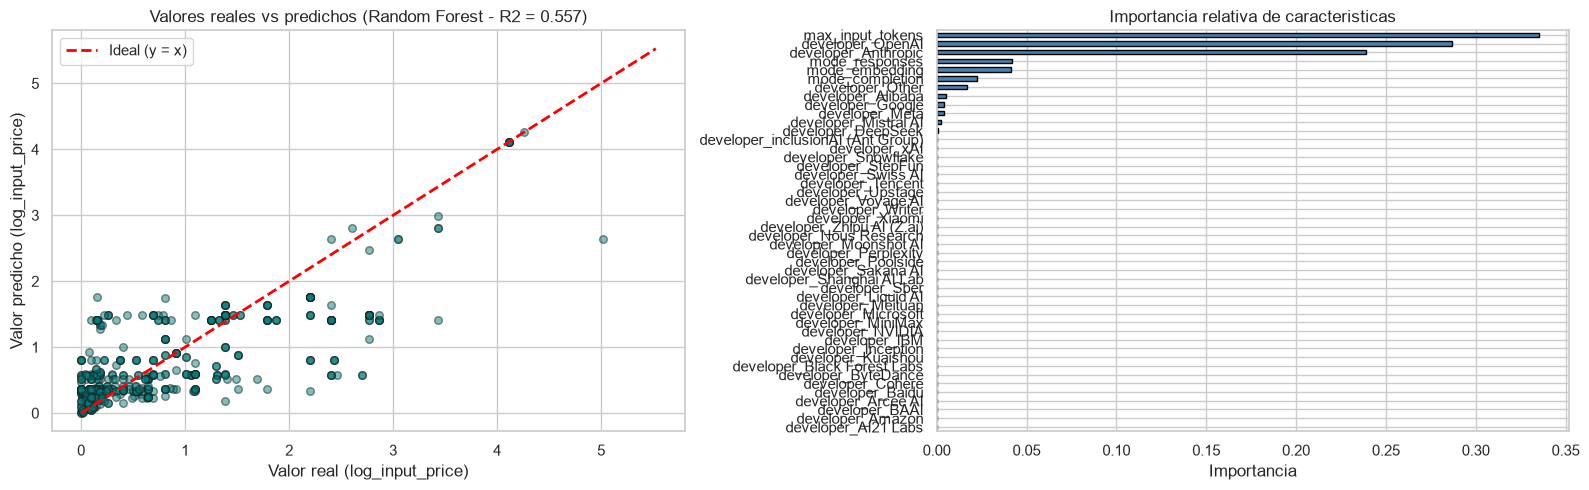

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

indices_sample = np.random.RandomState(42).choice(len(y_test), size=min(500, len(y_test)), replace=False)
axes[0].scatter(y_test.iloc[indices_sample], y_pred_rf[indices_sample], alpha=0.5, color="teal", edgecolor="k", s=30)
linea_x = np.linspace(y_test.min(), y_test.max(), 100)
axes[0].plot(linea_x, linea_x, color="red", linestyle="--", linewidth=2, label="Ideal (y = x)")
axes[0].set_title(f"Valores reales vs predichos (Random Forest - R2 = {r2_rf:.3f})")
axes[0].set_xlabel("Valor real (log_input_price)")
axes[0].set_ylabel("Valor predicho (log_input_price)")
axes[0].legend()

importancias = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)
importancias.plot(kind="barh", ax=axes[1], color="steelblue", edgecolor="black")
axes[1].set_title("Importancia relativa de caracteristicas")
axes[1].set_xlabel("Importancia")

plt.tight_layout()
plt.show()


### Conclusiones de la etapa de modelado

- El modelo **Random Forest Regressor** alcanzo un $R^2 = 0,5570$, superando a la regresion lineal ($R^2 = 0,3284$). Esto confirma que los precios en el mercado de IA presentan relaciones no lineales y variaciones segun el desarrollador y el tipo de modelo.
- En la escala real en dolares, el Random Forest logra un error absoluto medio de **$1,8184 USD por millon de tokens**, mejorando el error de $2,4380 USD del modelo lineal.
- Las variables de mayor peso al fijar el precio son la modalidad (`mode_embedding` vs `mode_chat`) y el desarrollador (OpenAI, Anthropic). En cambio, la variable `max_input_tokens` tuvo una importancia menor, lo que ratifica que el mercado no cobra mas solo por admitir ventanas de contexto mas amplias.


---
## Etapa 5: Concluir

Presentamos las respuestas a las 5 preguntas formuladas al inicio con la estructura de hallazgo, cifra e implicacion:

### Pregunta 1: Deflacion historica (2023-2026)
- **Hallazgo:** Existe una tendencia de reduccion sostenida de precios en todos los desarrolladores evaluados.
- **Cifra:** El precio por millon de tokens de entrada en OpenAI paso de 30,00 USD en GPT-4 a 0,15 USD en GPT-4o-mini (una caida del 99,5%), con una reduccion interanual media del 76,8% en el sector.
- **Implicacion:** La inferencia de modelos se esta convirtiendo en un servicio de bajo costo, por lo que las organizaciones deben evitar acuerdos plurianuales con tarifas fijas y revisar sus costos periodicamente.

### Pregunta 2: Disparidad de precios para Meta Llama 3
- **Hallazgo:** Alojar el mismo modelo de codigo abierto presenta diferencias notorias de costo segun el proveedor de nube.
- **Cifra:** Proveedores como DeepInfra ofrecen tarifas promedio de 0,52 USD por millon de tokens de entrada, mientras que en Azure AI asciende a 3,60 USD, generando una razon de dispersion de 6,92 veces (un sobrecosto superior al 500%).
- **Implicacion:** Implementar un enrutador inteligente de inferencia para enviar solicitudes al proveedor mas economico permite a las empresas reducir sus facturas de nube de forma inmediata.

### Pregunta 3: Ventana de contexto vs precio
- **Hallazgo:** La longitud de la ventana de contexto no incrementa el costo unitario por token.
- **Cifra:** La correlacion lineal de Pearson fue de $r = -0,019$ (practicamente nula). Modelos con 1 millon de tokens de contexto (como Gemini 1.5 Flash) manejan tarifas desde 0,075 USD por millon de tokens de entrada.
- **Implicacion:** Es viable procesar documentos extensos o bases de codigo completas sin recargo por token; la limitacion real radica en el tiempo de respuesta y latencia, no en la tarifa por token.

### Pregunta 4: Estructura por modalidad y salida vs entrada
- **Hallazgo:** Los tokens de salida tienen un costo superior al de los tokens de entrada, y los modelos de embedding son los mas economicos del catalogo.
- **Cifra:** En promedio el token de salida cuesta 3,45 veces mas que el de entrada. La mediana del precio de entrada es de 0,50 USD y la de salida es de 1,80 USD, mientras que los embeddings tienen una mediana de 0,02 USD.
- **Implicacion:** En optimizacion de costos de APIs, reducir la longitud de las respuestas mediante respuestas directas o formatos estructurados compactos genera mucho mas ahorro que recortar el prompt de entrada.

### Pregunta 5: Costos por consulta y atipicos
- **Hallazgo:** Para una consulta habitual de 1.000 tokens de entrada y 500 de salida, los modelos ligeros son muy accesibles, mientras que los modelos anteriores de gama alta representan valores atipicos costosos.
- **Cifra:** Una consulta en modelos ligeros cuesta alrededor de 0,00045 USD (menos de 50 centavos por cada mil consultas), frente a 0,045 USD en GPT-4 32k. Los registros atipicos segun la regla de Tukey representan el 7,82% del mercado.
- **Implicacion:** La mejor estrategia operativa es canalizar las tareas comunes a modelos compactos y reservar los modelos insignia unicamente para tareas de alta complejidad.
